# EDA: risco de falha de iluminação por bairro (Grupo 17)

Analise exploratoria da base cruzada em `applications/ml/data/processed/`, que junta o cadastro de
postes da Emlurb (2025) com os chamados de "lampada apagada" da Central 156 (2022-2025), por bairro.
Detalhes de como essa base foi montada (normalizacao, correcao dos codigos de servico que a Emlurb
trocou em 2024, etc.) estao em [`applications/ml/README.md`](../README.md) — este notebook assume
que esse cruzamento ja esta correto e foca em entender os dados antes de treinar qualquer modelo
(seção 2.0 do [`MACHINE_LEARNING.md`](../../../MACHINE_LEARNING.md)).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)

PALETA = {
    "primaria": "#2E6F8E",   # azul principal (series unica)
    "secundaria": "#6C757D", # cinza para contraste/comparacao
    "alerta": "#C1502E",     # usado so para destacar o achado da secao 1
}
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "figure.dpi": 110,
})

In [2]:
painel = pd.read_csv("../data/processed/risco_bairro_mes.csv")
postes = pd.read_csv("../data/processed/postes_por_bairro.csv")

print("painel (bairro x mes):", painel.shape)
print("postes_por_bairro:", postes.shape)
painel.head()

painel (bairro x mes): (4136, 15)
postes_por_bairro: (94, 6)


,bairro_norm,ano_mes,chamados_lampada_apagada,total_postes,postes_sem_id,potencia_media_w,pct_led,rpa,chamados_lag1,chamados_lag2,chamados_lag3,media_movel_3m,teve_chamado_mes_seguinte,chamados_mes_seguinte,conjunto
0,AFLITOS,2022-04,4,304.0,163.0,69.0,100.0,2,8.0,2.0,4.0,4.666667,1,2,treino
1,AFLITOS,2022-05,2,304.0,163.0,69.0,100.0,2,4.0,8.0,2.0,4.666667,1,5,treino
2,AFLITOS,2022-06,5,304.0,163.0,69.0,100.0,2,2.0,4.0,8.0,4.666667,1,5,treino
3,AFLITOS,2022-07,5,304.0,163.0,69.0,100.0,2,5.0,2.0,4.0,3.666667,1,5,treino
4,AFLITOS,2022-08,5,304.0,163.0,69.0,100.0,2,5.0,5.0,2.0,4.000000,1,1,treino


## 1. Chamados de "lâmpada apagada" por mês

Primeiro achado, antes de qualquer modelo: o volume de chamados **não é estável no período**.

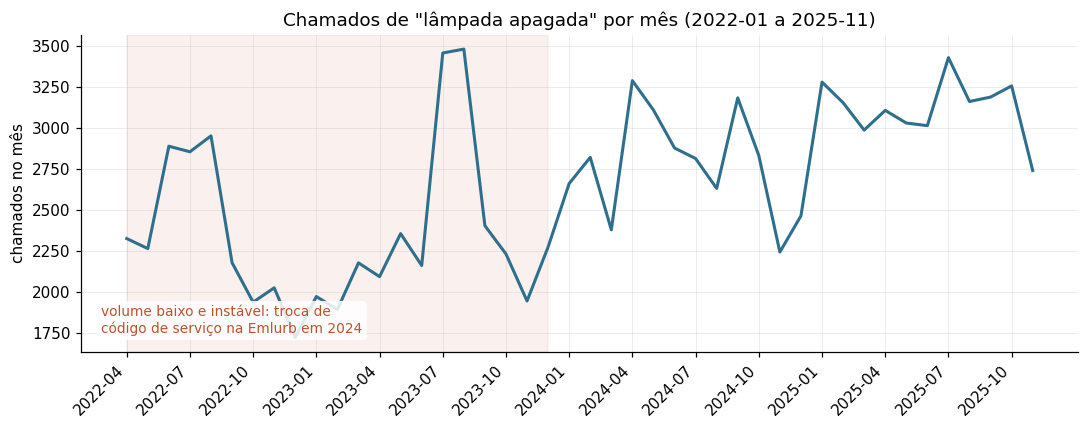

In [3]:
mensal = painel.groupby("ano_mes")["chamados_lampada_apagada"].sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mensal.index, mensal.values, color=PALETA["primaria"], linewidth=2)
ax.axvspan(0, mensal.index.get_loc("2023-12"), color=PALETA["alerta"], alpha=0.08)
ax.set_title('Chamados de "lâmpada apagada" por mês (2022-01 a 2025-11)')
ax.set_ylabel("chamados no mês")
ax.set_xticks(range(0, len(mensal), 3))
ax.set_xticklabels(mensal.index[::3], rotation=45, ha="right")
ax.text(
    0.02, 0.06, "volume baixo e instável: troca de\ncódigo de serviço na Emlurb em 2024",
    transform=ax.transAxes, fontsize=9, color=PALETA["alerta"],
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="none", alpha=0.85),
)
plt.tight_layout()
plt.show()

**Por que a área sombreada está quase em zero:** não é que não houve chamados de lâmpada apagada em
2022-2023 — é que a Emlurb trocou a tabela de códigos de serviço em 2024 (`GRUPOSERVICO_CODIGO`/
`SERVICO_CODIGO` mudaram de `17`/`25` para `4`/`55`, e o texto descritivo vem com a acentuação
corrompida nesses dois anos). O `preparar_dados.py` já trata isso filtrando pelos dois pares de
código. Ver seção 2 do [`applications/ml/README.md`](../README.md) para os números completos.

**Implicação para a modelagem:** apesar do filtro corrigido, o *volume* de chamados em 2024-2025 é
bem maior e mais estável que em 2022-2023 (que, mesmo com o filtro correto, ainda fica baixo nos
primeiros meses, por conta da transição) — vale considerar deixar 2022-2023 fora do treino, ou pelo
menos testar o modelo com e sem esses dois anos.

## 2. Chamados por bairro — top 10 e bottom 10

Onde o problema se concentra, somando os 47 meses do período.

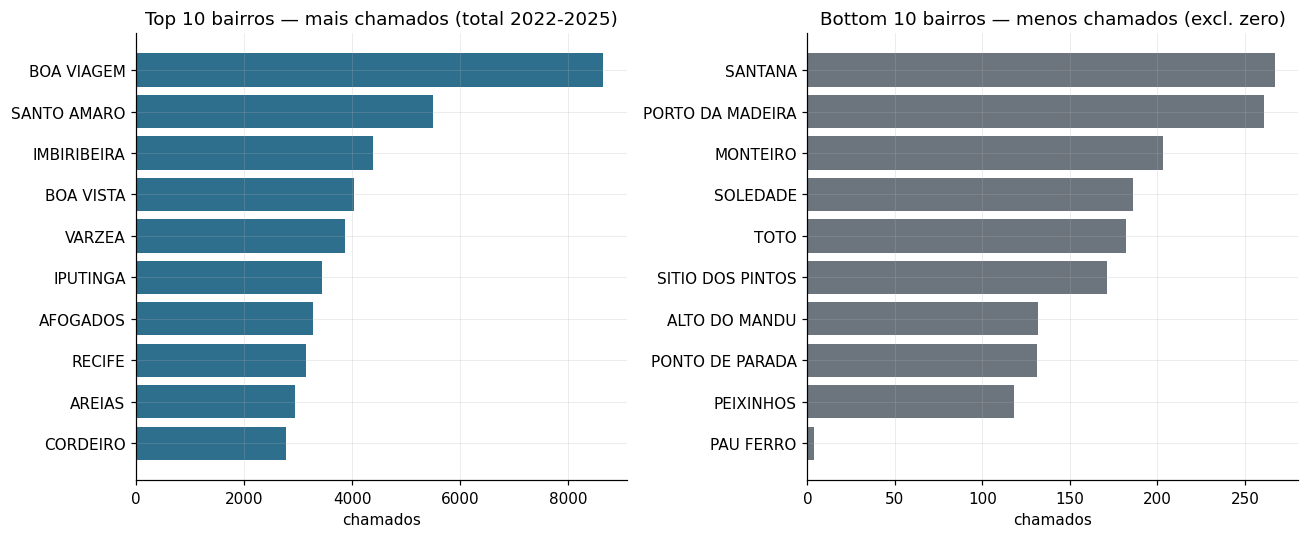

Bairros com ZERO chamados de lâmpada apagada no período inteiro: 0 de 94


In [4]:
por_bairro = painel.groupby("bairro_norm")["chamados_lampada_apagada"].sum().sort_values(ascending=False)
top10 = por_bairro.head(10)
bottom10 = por_bairro[por_bairro > 0].tail(10)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].barh(top10.index[::-1], top10.values[::-1], color=PALETA["primaria"])
axes[0].set_title("Top 10 bairros — mais chamados (total 2022-2025)")
axes[0].set_xlabel("chamados")

axes[1].barh(bottom10.index[::-1], bottom10.values[::-1], color=PALETA["secundaria"])
axes[1].set_title("Bottom 10 bairros — menos chamados (excl. zero)")
axes[1].set_xlabel("chamados")

plt.tight_layout()
plt.show()

zerados = (por_bairro == 0).sum()
print(f"Bairros com ZERO chamados de lâmpada apagada no período inteiro: {zerados} de {len(por_bairro)}")

**Leitura:** a distribuição é bem concentrada — alguns bairros carregam uma fração grande dos
chamados totais, o que é esperado (bairros maiores, mais populosos ou com mais postes tendem a gerar
mais chamados em termos absolutos). Isso sugere que o modelo pode se beneficiar de uma feature de
**exposição** (total de postes do bairro, já disponível em `total_postes`) para não confundir "bairro
grande" com "bairro de risco".

## 3. Tipo de lâmpada e % de LED por bairro

O cadastro de postes (2025) mostra o quanto cada bairro já migrou para LED.

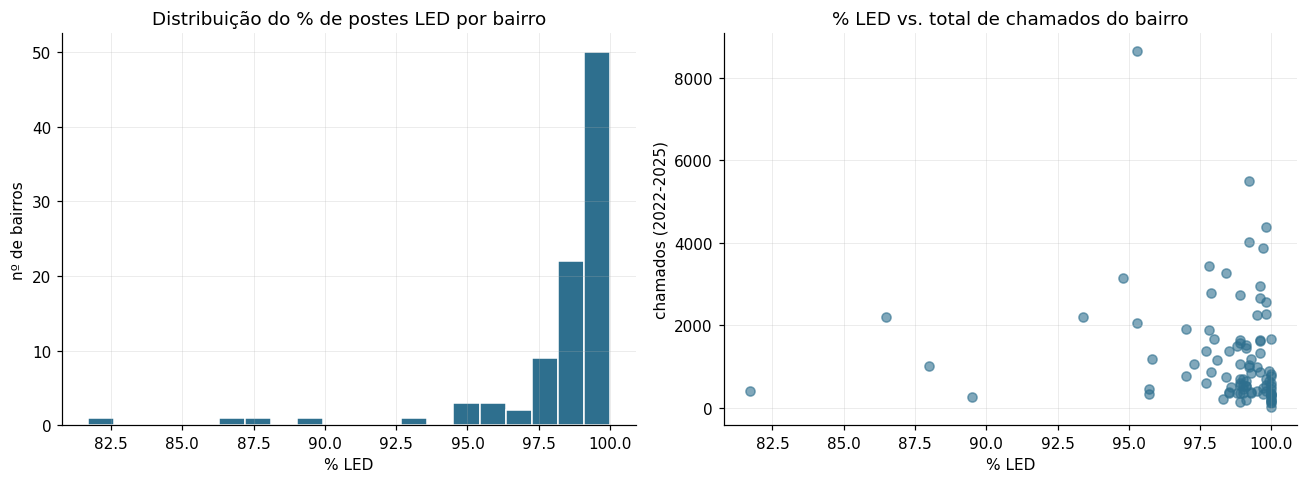

% LED médio entre bairros: 98.3
% LED mínimo: 81.7 | máximo: 100.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(postes["pct_led"], bins=20, color=PALETA["primaria"], edgecolor="white")
axes[0].set_title("Distribuição do % de postes LED por bairro")
axes[0].set_xlabel("% LED")
axes[0].set_ylabel("nº de bairros")

chamados_total = painel.groupby("bairro_norm")["chamados_lampada_apagada"].sum()
comparacao = postes.set_index("bairro_norm").join(chamados_total.rename("chamados_total"))

axes[1].scatter(comparacao["pct_led"], comparacao["chamados_total"], color=PALETA["primaria"], alpha=0.6)
axes[1].set_title("% LED vs. total de chamados do bairro")
axes[1].set_xlabel("% LED")
axes[1].set_ylabel("chamados (2022-2025)")

plt.tight_layout()
plt.show()

print("% LED médio entre bairros:", round(postes["pct_led"].mean(), 1))
print("% LED mínimo:", postes["pct_led"].min(), "| máximo:", postes["pct_led"].max())

**Leitura:** a maior parte dos bairros já está com % de LED bem alto (mediana alta, poucos bairros
destoando para baixo) — a cidade já avançou bastante na troca para LED. Não há uma relação linear
óbvia entre `% LED` e volume de chamados no gráfico de dispersão (o volume de chamados parece dominado
pelo tamanho do bairro, não pela tecnologia da lâmpada) — mas vale deixar `pct_led` como feature e
deixar o modelo decidir, em vez de descartar a priori.

## 4. Balanço da classe do rótulo (`teve_chamado_mes_seguinte`)

Esse é o ponto mais importante para a modelagem: como o rótulo binário se comporta por conjunto.

          proporcao_positiva  n_linhas
conjunto                              
teste                  0.953      1034
treino                 0.969      3102


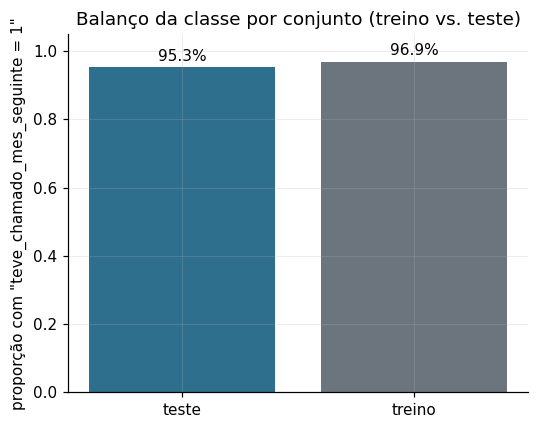

In [6]:
balanco = painel.groupby("conjunto")["teve_chamado_mes_seguinte"].agg(["mean", "count"])
balanco.columns = ["proporcao_positiva", "n_linhas"]
print(balanco.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
cores = [PALETA["primaria"], PALETA["secundaria"]]
ax.bar(balanco.index, balanco["proporcao_positiva"], color=cores)
for i, v in enumerate(balanco["proporcao_positiva"]):
    ax.text(i, v + 0.02, f"{v:.1%}", ha="center", fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_ylabel('proporção com "teve_chamado_mes_seguinte = 1"')
ax.set_title("Balanço da classe por conjunto (treino vs. teste)")
plt.tight_layout()
plt.show()

**Leitura:** treino e teste ficam bem próximos um do outro, o que é bom sinal — não há mudança
abrupta de distribuição entre os dois períodos, então o split temporal é razoável.

**Mas atenção:** essa proporção é o **oposto** do desbalanceamento clássico que a disciplina costuma
avisar (rótulo raro). Aqui, "ter pelo menos um chamado no mês seguinte" é o normal, não a exceção —
com ~94 bairros dividindo milhares de chamados por mês, quase todo bairro tem pelo menos um chamado
em quase todo mês. Prever "vai ter chamado" sempre como resposta já acerta a maioria das vezes — a
seção 5 mostra o quanto isso prejudica o classificador binário, e qual alternativa resolve.

## 5. Defasagem (lag) e a decisão de alvo: classificação binária vs. contagem

O `preparar_dados.py` agora inclui features de histórico por bairro (`chamados_lag1/2/3`,
`media_movel_3m`). Antes de escrever o `treinar.py`, a pergunta é: qual alvo essas features
conseguem prever melhor — o binário `teve_chamado_mes_seguinte` ou a contagem bruta
`chamados_mes_seguinte`?

                          correlação com o binário  correlação com a contagem
pct_led                                     -0.076                     -0.085
potencia_media_w                             0.108                      0.091
rpa                                         -0.002                      0.268
total_postes                                 0.036                      0.796
chamados_lag3                                0.127                      0.831
chamados_lag2                                0.135                      0.837
chamados_lag1                                0.141                      0.845
media_movel_3m                               0.140                      0.876
chamados_lampada_apagada                     0.146                      0.885


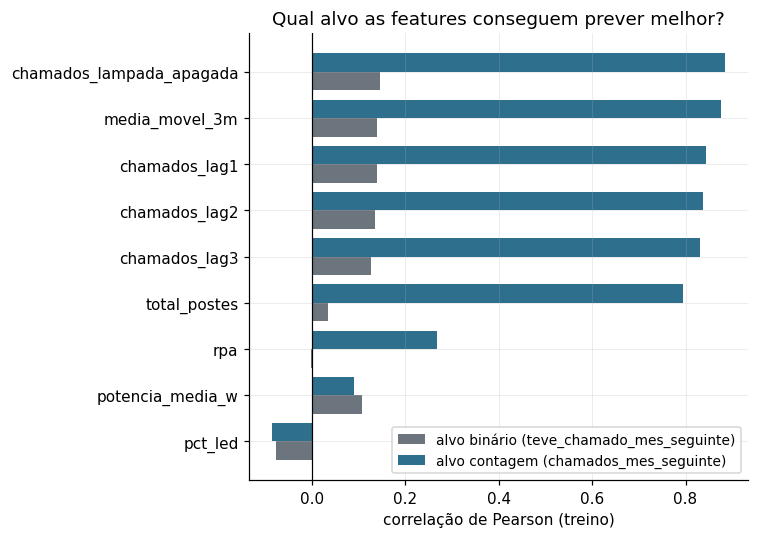

In [7]:
features = [
    "chamados_lampada_apagada", "chamados_lag1", "chamados_lag2", "chamados_lag3",
    "media_movel_3m", "total_postes", "potencia_media_w", "pct_led", "rpa",
]
treino = painel[painel["conjunto"] == "treino"]

corr_binario = treino[features + ["teve_chamado_mes_seguinte"]].corr()["teve_chamado_mes_seguinte"].drop("teve_chamado_mes_seguinte")
corr_contagem = treino[features + ["chamados_mes_seguinte"]].corr()["chamados_mes_seguinte"].drop("chamados_mes_seguinte")

comparacao_alvo = pd.DataFrame({
    "correlação com o binário": corr_binario,
    "correlação com a contagem": corr_contagem,
}).sort_values("correlação com a contagem")

print(comparacao_alvo.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
y = range(len(comparacao_alvo))
ax.barh([p - 0.2 for p in y], comparacao_alvo["correlação com o binário"], height=0.4,
        color=PALETA["secundaria"], label="alvo binário (teve_chamado_mes_seguinte)")
ax.barh([p + 0.2 for p in y], comparacao_alvo["correlação com a contagem"], height=0.4,
        color=PALETA["primaria"], label="alvo contagem (chamados_mes_seguinte)")
ax.set_yticks(list(y))
ax.set_yticklabels(comparacao_alvo.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("correlação de Pearson (treino)")
ax.set_title("Qual alvo as features conseguem prever melhor?")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**Resultado:** contra o alvo binário, toda e qualquer feature fica abaixo de 0,15 de correlação —
nada ali é realmente informativo, inclusive o próprio histórico do bairro. Contra a **contagem**,
a história é completamente diferente: `chamados_lampada_apagada` do mês atual chega a **0,89**,
`media_movel_3m` a **0,88**, e até `total_postes` (uma feature estática do cadastro) chega a **0,80**.

**Decisão de alvo: o modelo principal vai prever a contagem de chamados do mês seguinte
(regressão/ranking), não a classificação binária.** A classificação binária neste nível de
agregação (bairro × mês) está quebrada pela prevalência de ~95%, não importa a feature; a contagem
preserva toda a informação que o histórico de chamados carrega. O `treinar.py` deve:

1. Treinar `RandomForestRegressor`/`GradientBoostingRegressor` prevendo `chamados_mes_seguinte`,
   comparando com a baseline simples (`media_movel_3m`, ou "chamados do bairro no ano anterior").
2. Converter a previsão em **risco de 0 a 1** normalizando por percentil entre os bairros do mesmo
   mês (bairro no percentil 90+ de chamados previstos = risco alto) — mantém o contrato já
   documentado no `MACHINE_LEARNING.md` (potência 90/80/70 por faixa de risco).
3. Avaliar com a **"precisão no top 10%"** da seção 4 do `MACHINE_LEARNING.md`, que já é uma métrica
   de ranking — ela se encaixa na regressão de forma muito mais natural do que na classificação
   binária original.

O rótulo binário (`teve_chamado_mes_seguinte`) continua na base, documentado, caso alguém queira
comparar as duas abordagens no relatório — mas não é mais o alvo principal.